### ZADANIE 1

In [1]:
import numpy as np
import matplotlib.pyplot as plt
x=lambda n: np.linspace(1/n,1,n)
M=1000
def estimate_beta_1(x_vect,y_vect):
    num=0
    den=0
    mean=np.mean(x_vect)
    for i in range(len(x_vect)):
        num+=(x_vect[i] - mean)*y_vect[i]
        den+=(x_vect[i]-mean)**2
    return num/den
def estimate_beta_0(x_vect,y_vect):
    return np.mean(y_vect) - estimate_beta_1(x_vect,y_vect)*np.mean(x_vect)

In [28]:
def monte_carlo(n):
    out=[]
    epsilon=np.random.normal(0,1,n*M)
    for i in range(M):
        y=[]
        beta_0=2
        beta_1=-1/2
        y=[beta_0 + beta_1*x(n)[j] + epsilon[j*n:(j+1)*n] for j in range(n)]
        out.append((estimate_beta_1(x(n),y),estimate_beta_0(x(n),y)))
    return out

def check_parameters():
    #x_ax=[10*i for i in range(1,51)]
    #data=[monte_carlo(i) for i in range(10,510,10)]
    data=[monte_carlo(510)]
    #mean=[np.mean(data[i][0]) for i in range(len(data))]
    #var= [np.var(data[i][0]) for i in range(len(data))]
    #bias=[np.mean(data[i][0])+(1/2) for i in range(len(data))]
    #mse =[np.mean((data[i][0]+1/2)**2) for i in range(len(data))]
    #plt.scatter(x_ax,mean)
    #plt.plot()
    #plt.scatter(x_ax,var)
    #plt.plot()
    #plt.scatter(x_ax,bias)
    #plt.plot()
    #plt.scatter(x_ax,mse)
    #plt.plot()    
check_parameters()




### ZADANIE 5


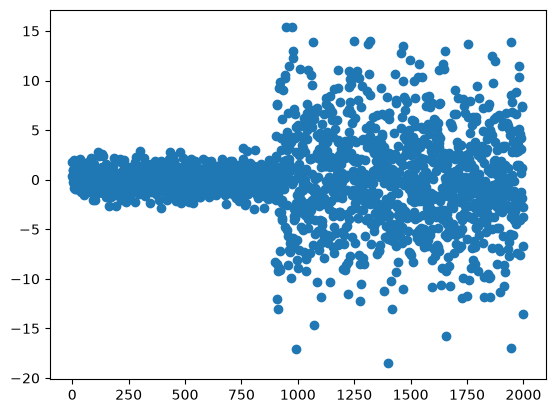

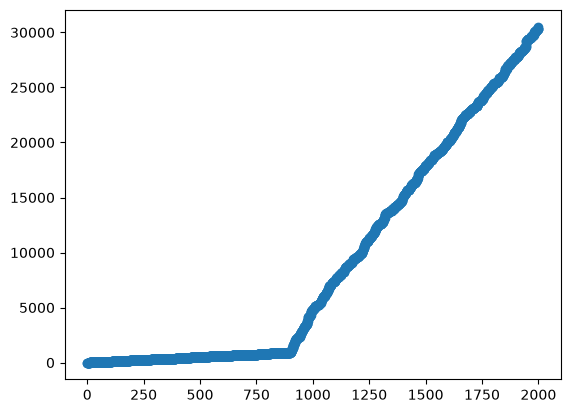

In [5]:
def generator(T,k):
    var1=np.random.normal(0,1,k)
    var2=np.random.normal(0,5,T-k)
    out=[]
    for i in range(k):
        out.append(var1[i])
    for i in range(T-k):
        out.append(var2[i])
    return out
def C(list):
    return np.cumsum(np.asarray(list.copy())**2)
T=2000
data=generator(T,900)
space=[i for i in range(T)]
Y=C(data)
plt.scatter((space),data[:len(data)])
plt.show()
plt.scatter(space,Y)        
plt.show()


              

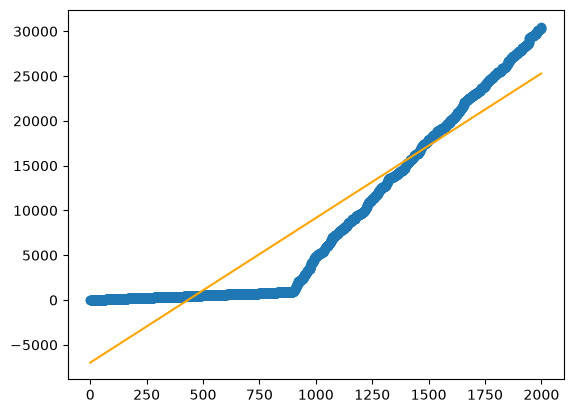

In [6]:
def beta_1(x_vect,y_vect):
    mean=np.mean(x_vect)
    num=np.dot(np.asarray(x_vect)-mean,np.asarray(y_vect))
    den=np.sum((np.asarray(x_vect)-mean)**2)
    return num/den
def beta_0(x_vect,y_vect):
    return np.mean(y_vect) - beta_1(x_vect,y_vect)*np.mean(x_vect)
wrong_plot=[beta_0(space,Y) + beta_1(space,Y)*i for i in range(len(space))]
plt.plot(space,wrong_plot,color="orange")
plt.scatter(space,Y)
plt.show()




In [7]:
def square_error(list,predicted_list):
    return np.sum((np.asarray(list)-np.asarray(predicted_list))**2)
sum=[]

def calc_eff_error(k,T,data):
    divide=(data[:k],data[k:])
    sample_1=C(divide[0])
    sample_2=C(divide[1])

    sample_1_space=[i for i in range(k)]
    sample_1_beta_0=beta_0(sample_1_space,sample_1)
    sample_1_beta_1=beta_1(sample_1_space,sample_1)
    
    sample_2_space=[i for i in range(k,T)]
    sample_2_beta_0=beta_0(sample_2_space,sample_2)
    sample_2_beta_1=beta_1(sample_2_space,sample_2)
    
    sample_1_error=square_error(sample_1,[sample_1_beta_0 + sample_1_beta_1*i for i in sample_1_space])
    sample_2_error=square_error(sample_2,[sample_2_beta_0 + sample_2_beta_1*i for i in sample_2_space])
    return sample_1_error + sample_2_error
for k in range(2,T-2):
    sum.append(calc_eff_error(k,T,data))
print(np.argmin(sum))




917


In [ ]:
sigma_prop=[2,4,8,16]
pivot_prop=[1/3,1/2,2/3]

def monte_carlo():
    for i in range(1000):
        data=generator()
